
# Análisis Multivariado de Varianza
## Ejemplo: Comparación de Métodos de Enseñanza
## Actividad MANOVA
### Dr. Hugo García Tecocoatzi

In [1]:
# Bibliotecas necesarias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from scipy import stats
from sklearn.datasets import load_iris, load_wine, load_diabetes # Necesaria para la actividad
from scipy.stats import f_oneway
from statsmodels.multivariate.manova import MANOVA
from statsmodels.stats.multicomp import pairwise_tukeyhsd

import statsmodels.api as sm
from statsmodels.formula.api import ols

%matplotlib inline

In [2]:
# Generar datos sintéticos para el ejemplo
np.random.seed(42)

# Parámetros
n_por_grupo = 30
grupos = ['A', 'B', 'C']

# Método A: Enseñanza tradicional
# Matemáticas: media 75, Lectura: media 70
mat_A = np.random.normal(75, 8, n_por_grupo)
lec_A = np.random.normal(70, 8, n_por_grupo)

# Método B: Enseñanza activa
# Matemáticas: media 82, Lectura: media 78
mat_B = np.random.normal(82, 8, n_por_grupo)
lec_B = np.random.normal(78, 8, n_por_grupo)

# Método C: Enseñanza híbrida
# Matemáticas: media 78, Lectura: media 75
mat_C = np.random.normal(78, 8, n_por_grupo)
lec_C = np.random.normal(75, 8, n_por_grupo)

# Crear DataFrame
df = pd.DataFrame({
    'Metodo': ['A']*n_por_grupo + ['B']*n_por_grupo + ['C']*n_por_grupo,
    'Matematicas': np.concatenate([mat_A, mat_B, mat_C]),
    'Lectura': np.concatenate([lec_A, lec_B, lec_C])
})

# Asegurar que las calificaciones estén en rango [0, 100]
df['Matematicas'] = np.clip(df['Matematicas'], 0, 100)
df['Lectura'] = np.clip(df['Lectura'], 0, 100)

print("Datos generados exitosamente")
print(f"Forma del dataset: {df.shape}")
print(f"Grupos: {df['Metodo'].unique()}")
df.head(10)

Datos generados exitosamente
Forma del dataset: (90, 3)
Grupos: <StringArray>
['A', 'B', 'C']
Length: 3, dtype: str


,Metodo,Matematicas,Lectura
0,A,78.973713,65.186347
1,A,73.893886,84.818225
2,A,80.181508,69.892022
3,A,87.184239,61.538313
4,A,73.126773,76.580359
5,A,73.126904,60.233251
6,A,87.633703,71.670909
7,A,81.139478,54.322639
8,A,71.244205,59.374512
9,A,79.340480,71.574890


In [3]:
#  Estadísticas descriptivas por grupo
print("ESTADÍSTICAS DESCRIPTIVAS POR GRUPO: \n")

estadisticas = df.groupby('Metodo').agg({
    'Matematicas': ['mean', 'std', 'min', 'max'],
    'Lectura': ['mean', 'std', 'min', 'max']
}).round(2)

print(estadisticas)

ESTADÍSTICAS DESCRIPTIVAS POR GRUPO: 

       Matematicas                     Lectura                    
              mean   std    min    max    mean   std    min    max
Metodo                                                            
A            73.49  7.20  59.69  87.63   69.03  7.45  54.32  84.82
B            82.10  7.94  61.04  94.52   77.84  7.27  62.65  97.71
C            77.24  8.19  65.14  95.52   77.23  7.58  65.47  96.76


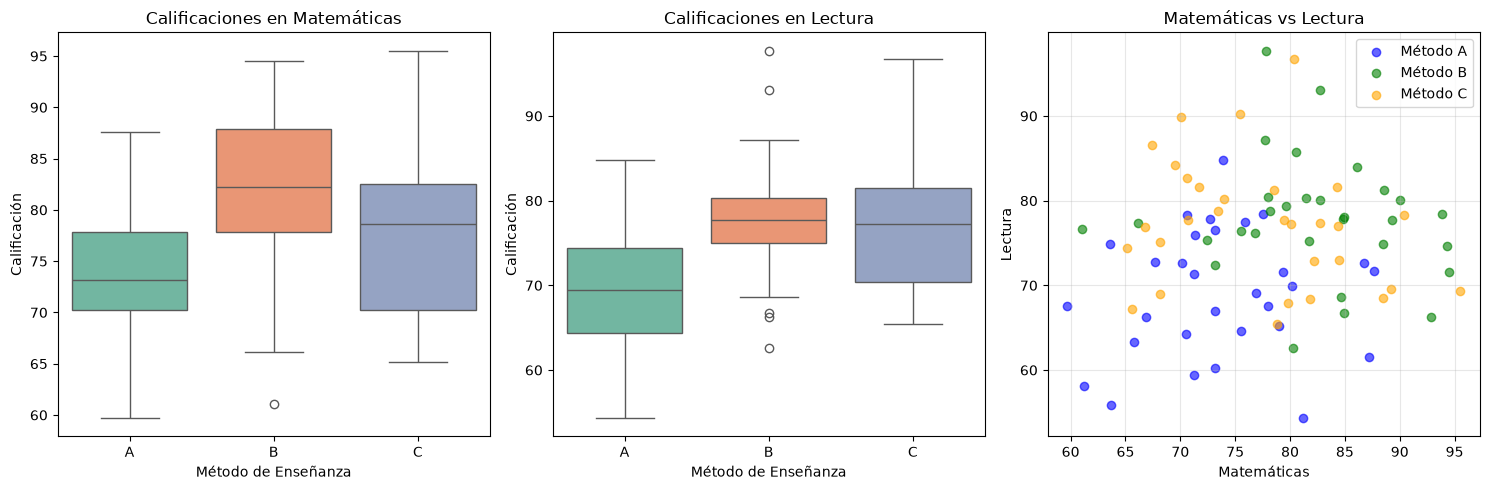

In [4]:
# Visualización 
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Boxplot Matemáticas
sns.boxplot(x='Metodo', y='Matematicas', data=df, ax=axes[0], palette='Set2')
axes[0].set_title('Calificaciones en Matemáticas')
axes[0].set_xlabel('Método de Enseñanza')
axes[0].set_ylabel('Calificación')

# Boxplot Lectura
sns.boxplot(x='Metodo', y='Lectura', data=df, ax=axes[1], palette='Set2')
axes[1].set_title('Calificaciones en Lectura')
axes[1].set_xlabel('Método de Enseñanza')
axes[1].set_ylabel('Calificación')

# Scatter plot Matemáticas vs Lectura
colors = {'A': 'blue', 'B': 'green', 'C': 'orange'}
for metodo in df['Metodo'].unique():
    subset = df[df['Metodo'] == metodo]
    axes[2].scatter(subset['Matematicas'], subset['Lectura'], 
                    alpha=0.6, label=f'Método {metodo}', color=colors[metodo])
axes[2].set_xlabel('Matemáticas')
axes[2].set_ylabel('Lectura')
axes[2].set_title('Matemáticas vs Lectura')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

MATRIZ DE CORRELACIÓN

             Matematicas  Lectura
Matematicas       1.0000   0.0886
Lectura           0.0886   1.0000


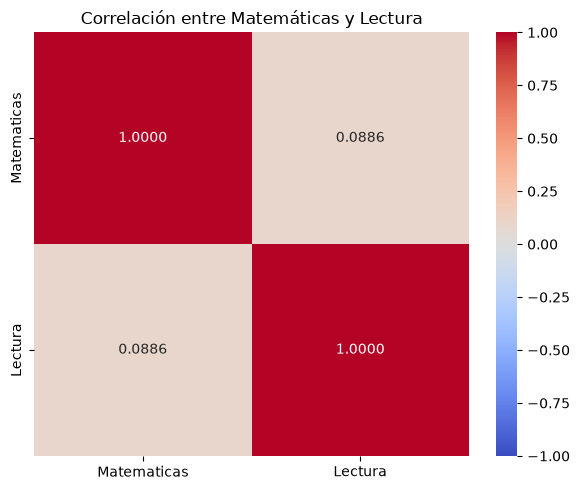

In [5]:
# Matriz de correlación
print("MATRIZ DE CORRELACIÓN\n")
print(df[['Matematicas', 'Lectura']].corr().round(4))

# Visualización
plt.figure(figsize=(6, 5))
sns.heatmap(df[['Matematicas', 'Lectura']].corr(), 
            annot=True, cmap='coolwarm', center=0, 
            vmin=-1, vmax=1, fmt='.4f')
plt.title('Correlación entre Matemáticas y Lectura')
plt.tight_layout()
plt.show()

In [6]:
#  MANOVA - Prueba principal
print("MANOVA \n")

# Ajustar MANOVA
manova = MANOVA.from_formula('Matematicas + Lectura ~ Metodo', data=df)
resultado = manova.mv_test()

print(resultado)

MANOVA 

                   Multivariate linear model
                                                               
---------------------------------------------------------------
       Intercept         Value  Num DF  Den DF  F Value  Pr > F
---------------------------------------------------------------
          Wilks' lambda  0.0146 2.0000 86.0000 2907.3547 0.0000
         Pillai's trace  0.9854 2.0000 86.0000 2907.3547 0.0000
 Hotelling-Lawley trace 67.6129 2.0000 86.0000 2907.3547 0.0000
    Roy's greatest root 67.6129 2.0000 86.0000 2907.3547 0.0000
---------------------------------------------------------------
                                                               
---------------------------------------------------------------
           Metodo         Value  Num DF  Den DF  F Value Pr > F
---------------------------------------------------------------
            Wilks' lambda 0.6317 4.0000 172.0000 11.1040 0.0000
           Pillai's trace 0.3790 4.0000 174.0000 1

In [7]:
#  Extraer resultados de los cuatro estadísticos
print("=== RESULTADOS DE LOS CUATRO ESTADÍSTICOS ===\n")

# Extraer resultados del MANOVA
resultados_mv = manova.mv_test().results['Metodo']['stat']

print("Estadísticos de prueba:")
print(resultados_mv.round(4))

=== RESULTADOS DE LOS CUATRO ESTADÍSTICOS ===

Estadísticos de prueba:
                           Value Num DF      Den DF    F Value Pr > F
Wilks' lambda           0.631651      4       172.0  11.104044    0.0
Pillai's trace          0.379027    4.0       174.0  10.171469    0.0
Hotelling-Lawley trace  0.566246      4  102.169014  12.128592    0.0
Roy's greatest root     0.534625      2          87  23.256178    0.0


In [8]:
# Interpretación de los cuatro estadísticos del MANOVA
print("INTERPRETACIÓN DE RESULTADOS\n")
for estadistico in resultados_mv.index:
    p_valor = float(resultados_mv.loc[estadistico, 'Pr > F'])
    valor = float(resultados_mv.loc[estadistico, 'Value'])
    decision = "Significativo" if p_valor < 0.05 else "No significativo"
    print(f"{estadistico}: valor = {valor:.4f}, p = {p_valor:.3e} → {decision}")

p_pillai = float(resultados_mv.loc["Pillai's trace", 'Pr > F'])
print("\nConclusión:")
if p_pillai < 0.05:
    print("Rechazo H₀: hay diferencias entre los métodos en el conjunto de Matemáticas y Lectura.")
else:
    print("No encuentro evidencia suficiente para rechazar H₀.")

INTERPRETACIÓN DE RESULTADOS

Wilks' lambda: valor = 0.6317, p = 4.912e-08 → Significativo
Pillai's trace: valor = 0.3790, p = 2.012e-07 → Significativo
Hotelling-Lawley trace: valor = 0.5662, p = 4.182e-08 → Significativo
Roy's greatest root: valor = 0.5346, p = 8.108e-09 → Significativo

Conclusión:
Rechazo H₀: hay diferencias entre los métodos en el conjunto de Matemáticas y Lectura.


In [9]:
# ANOVA univariado post-hoc (con corrección de Bonferroni)
print("=== ANOVA UNIVARIADO POST-HOC ===\n")

# ANOVA para Matemáticas
print("ANOVA para Matemáticas:")
modelo_mat = ols('Matematicas ~ Metodo', data=df).fit()
anova_mat = sm.stats.anova_lm(modelo_mat, typ=2)
print(anova_mat.round(4))

# ANOVA para Lectura
print("\n ANOVA para Lectura:")
modelo_lec = ols('Lectura ~ Metodo', data=df).fit()
anova_lec = sm.stats.anova_lm(modelo_lec, typ=2)
print(anova_lec.round(4))

# Corrección de Bonferroni
alpha = 0.05
alpha_bonferroni = alpha / 2  # 2 variables dependientes

print(f"\n Corrección de Bonferroni:")
print(f"   α original = {alpha}")
print(f"   α ajustado = {alpha_bonferroni}")

# Interpretación
p_mat = anova_mat.loc['Metodo', 'PR(>F)']
p_lec = anova_lec.loc['Metodo', 'PR(>F)']

print(f"\n   Matemáticas: p = {p_mat:.4f} → {'Significativo' if p_mat < alpha_bonferroni else 'No significativo'}")
print(f"   Lectura: p = {p_lec:.4f} → {'Significativo' if p_lec < alpha_bonferroni else 'No significativo'}")

=== ANOVA UNIVARIADO POST-HOC ===

ANOVA para Matemáticas:
             sum_sq    df      F  PR(>F)
Metodo    1117.7714   2.0  9.215  0.0002
Residual  5276.5085  87.0    NaN     NaN

 ANOVA para Lectura:
             sum_sq    df        F  PR(>F)
Metodo    1451.7091   2.0  13.1348     0.0
Residual  4807.8024  87.0      NaN     NaN

 Corrección de Bonferroni:
   α original = 0.05
   α ajustado = 0.025

   Matemáticas: p = 0.0002 → Significativo
   Lectura: p = 0.0000 → Significativo


In [10]:
#  Comparaciones múltiples post-hoc (Tukey HSD)
print(" COMPARACIONES MÚLTIPLES POST-HOC (TUKEY HSD) \n")

# Tukey para Matemáticas
print("Tukey HSD para Matemáticas:")
tukey_mat = pairwise_tukeyhsd(df['Matematicas'], df['Metodo'], alpha=0.05)
print(tukey_mat)

print("\n Tukey HSD para Lectura:")
tukey_lec = pairwise_tukeyhsd(df['Lectura'], df['Metodo'], alpha=0.05)
print(tukey_lec)

 COMPARACIONES MÚLTIPLES POST-HOC (TUKEY HSD) 

Tukey HSD para Matemáticas:


Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj   lower  upper  reject
---------------------------------------------------
     A      B   8.6083 0.0001  3.8136 13.403   True
     A      C   3.7455 0.1558 -1.0492 8.5402  False
     B      C  -4.8627 0.0461 -9.6574 -0.068   True
---------------------------------------------------

 Tukey HSD para Lectura:
Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
     A      B   8.8073    0.0  4.2305 13.3841   True
     A      C   8.1996 0.0001  3.6228 12.7764   True
     B      C  -0.6077 0.9463 -5.1845  3.9691  False
----------------------------------------------------


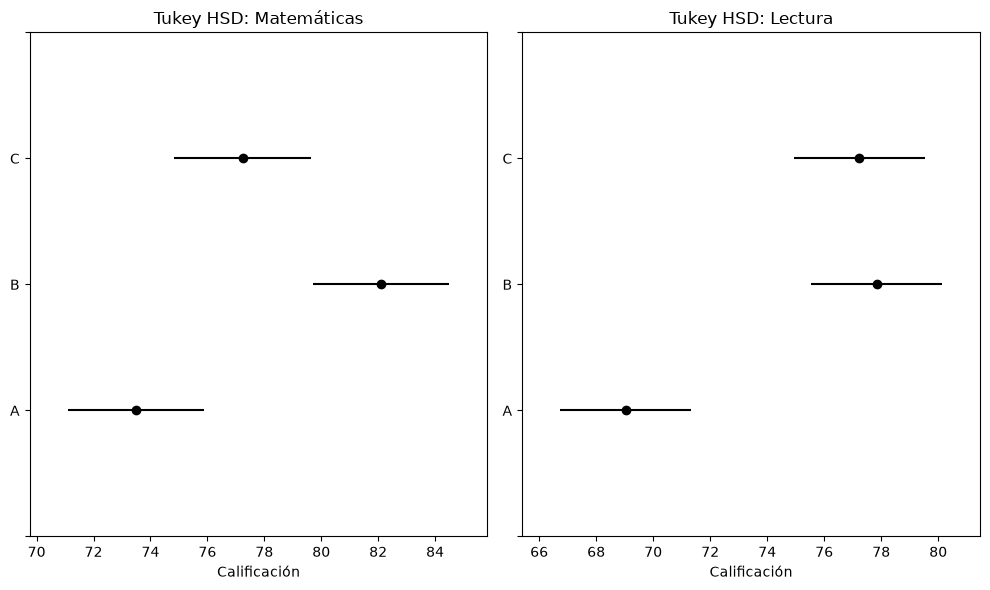

In [11]:
# Visualización de Tukey HSD
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Tukey Matemáticas
tukey_mat.plot_simultaneous(ax=axes[0])
axes[0].set_title('Tukey HSD: Matemáticas')
axes[0].set_xlabel('Calificación')

# Tukey Lectura
tukey_lec.plot_simultaneous(ax=axes[1])
axes[1].set_title('Tukey HSD: Lectura')
axes[1].set_xlabel('Calificación')

plt.tight_layout()
plt.show()

In [12]:
# Verificación de normalidad multivariada por grupo
# Mardia: covarianza con divisor n; aproximación asintótica.
def mardia_test(data, alpha=0.05):
    data = np.asarray(data, dtype=float)
    n, p = data.shape
    centered = data - data.mean(axis=0)
    covariance = centered.T @ centered / n
    products = centered @ np.linalg.inv(covariance) @ centered.T
    b1p = np.mean(products ** 3)
    b2p = np.mean(np.diag(products) ** 2)
    skewness_stat = n * b1p / 6
    if n < 20:
        correction = (p + 1) * (n + 1) * (n + 3) / (n * ((n + 1) * (p + 1) - 6))
        skewness_stat *= correction
    kurtosis_stat = (b2p - p * (p + 2)) / np.sqrt(8 * p * (p + 2) / n)
    return {
        'Skewness statistic': skewness_stat,
        'Skewness p-value': stats.chi2.sf(skewness_stat, p * (p + 1) * (p + 2) / 6),
        'Kurtosis statistic': kurtosis_stat,
        'Kurtosis p-value': 2 * stats.norm.sf(abs(kurtosis_stat))
    }

print("NORMALIDAD MULTIVARIADA: PRUEBA DE MARDIA\n")
for metodo in df['Metodo'].unique():
    subset = df.loc[df['Metodo'] == metodo, ['Matematicas', 'Lectura']].to_numpy()
    resultado_mardia = mardia_test(subset)
    print(f"Método {metodo}:")
    for key, value in resultado_mardia.items():
        print(f"  {key}: {value:.4f}")
    compatible = (resultado_mardia['Skewness p-value'] > 0.05
                  and resultado_mardia['Kurtosis p-value'] > 0.05)
    print("  No se rechaza la normalidad multivariada.\n" if compatible
          else "  Hay evidencia contra la normalidad multivariada.\n")

NORMALIDAD MULTIVARIADA: PRUEBA DE MARDIA

Método A:
  Skewness statistic: 2.1403
  Skewness p-value: 0.7100
  Kurtosis statistic: -0.8187
  Kurtosis p-value: 0.4130
  No se rechaza la normalidad multivariada.

Método B:
  Skewness statistic: 4.4518
  Skewness p-value: 0.3483
  Kurtosis statistic: 0.1412
  Kurtosis p-value: 0.8877
  No se rechaza la normalidad multivariada.

Método C:
  Skewness statistic: 3.4828
  Skewness p-value: 0.4805
  Kurtosis statistic: -0.5902
  Kurtosis p-value: 0.5551
  No se rechaza la normalidad multivariada.



In [13]:
#  Verificación de supuestos - Homogeneidad de covarianzas (Box's M)
print(" Homogeneidad de Matrices de Covarianza (Box's M) \n")

def box_m_test(data, groups):
    """
    Implementación del test M de Box
    """
    group_names = groups.unique()
    k = len(group_names)
    p = data.shape[1]
    
    # Tamaños de muestra
    ns = [len(data[groups == g]) for g in group_names]
    n_total = sum(ns)
    
    # Matrices de covarianza por grupo
    covs = []
    for g in group_names:
        subset = data[groups == g]
        covs.append(np.cov(subset, rowvar=False))
    
    # Covarianza pooled
    pooled_cov = sum([(n-1) * cov for n, cov in zip(ns, covs)]) / (n_total - k)
    
    # Estadístico M
    M = (n_total - k) * np.log(np.linalg.det(pooled_cov))
    for n, cov in zip(ns, covs):
        M -= (n - 1) * np.log(np.linalg.det(cov))
    
    # Factor de corrección
    c = (2 * p**2 + 3 * p - 1) / (6 * (p + 1) * (k - 1))
    c *= sum([1/(n-1) for n in ns]) - 1/(n_total - k)
    
    # Estadístico de prueba
    chi2_stat = M * (1 - c)
    
    # Grados de libertad
    df = p * (p + 1) * (k - 1) / 2
    
    # p-valor
    p_value = stats.chi2.sf(chi2_stat, df)
    
    return {
        'M statistic': M,
        'Chi-square': chi2_stat,
        'df': df,
        'p-value': p_value
    }

# Aplicar Box's M
resultado_box = box_m_test(df[['Matematicas', 'Lectura']], df['Metodo'])
print("Resultados del test M de Box:")
for key, value in resultado_box.items():
    print(f"  {key}: {value:.4f}")

if resultado_box['p-value'] > 0.05:
    print("\n✅ No se rechaza H₀: Las matrices de covarianza son homogéneas")
else:
    print("\n⚠️ Se rechaza H₀: Posible violación de homogeneidad de covarianzas")
    print("   → Considerar usar Pillai's Trace (más robusto)")

 Homogeneidad de Matrices de Covarianza (Box's M) 

Resultados del test M de Box:
  M statistic: 2.3240
  Chi-square: 2.2469
  df: 6.0000
  p-value: 0.8957

✅ No se rechaza H₀: Las matrices de covarianza son homogéneas


In [14]:
#  Preguntas de análisis
print(" PREGUNTAS DE ANÁLISIS:")
print("\n1. ¿Cuál de los cuatro estadísticos MANOVA es más apropiado y por qué?")
print("2. ¿Qué variable dependiente contribuye más a las diferencias entre grupos?")
print("3. ¿Qué pares de grupos son significativamente diferentes?")
print("4. ¿Se cumplen los supuestos del MANOVA? ¿Qué implicaciones tiene?")
print("5. ¿Cómo se relacionan los resultados del LDA con los del MANOVA?")



 PREGUNTAS DE ANÁLISIS:

1. ¿Cuál de los cuatro estadísticos MANOVA es más apropiado y por qué?
2. ¿Qué variable dependiente contribuye más a las diferencias entre grupos?
3. ¿Qué pares de grupos son significativamente diferentes?
4. ¿Se cumplen los supuestos del MANOVA? ¿Qué implicaciones tiene?
5. ¿Cómo se relacionan los resultados del LDA con los del MANOVA?


### Análisis discriminante lineal (LDA) del ejemplo

Para contestar la última pregunta, agregué un LDA con las dos calificaciones. El MANOVA evalúa si los grupos tienen distintas medias conjuntas; el LDA permite observar cómo se separan al combinar las variables.

Proporción de separación por eje:
LD1: 94.42%
LD2: 5.58%

Promedios de las coordenadas por método:


          LD1    LD2
Metodo              
A       0.976  0.069
B      -0.734  0.171
C      -0.242 -0.240


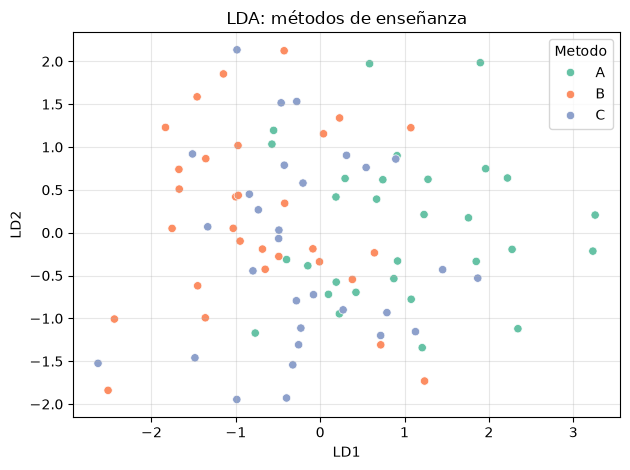

In [15]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

lda_metodos = LinearDiscriminantAnalysis(n_components=2)
coordenadas_metodos = lda_metodos.fit_transform(df[['Matematicas', 'Lectura']], df['Metodo'])
df_lda_metodos = pd.DataFrame(coordenadas_metodos, columns=['LD1', 'LD2'])
df_lda_metodos['Metodo'] = df['Metodo'].to_numpy()
print("Proporción de separación por eje:")
for i, proporcion in enumerate(lda_metodos.explained_variance_ratio_, start=1):
    print(f"LD{i}: {proporcion:.2%}")
print("\nPromedios de las coordenadas por método:")
print(df_lda_metodos.groupby('Metodo')[['LD1', 'LD2']].mean().round(3))
sns.scatterplot(data=df_lda_metodos, x='LD1', y='LD2', hue='Metodo', palette='Set2')
plt.title('LDA: métodos de enseñanza')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Mis respuestas al ejemplo de métodos de enseñanza

**1. ¿Cuál de los cuatro estadísticos MANOVA es más apropiado y por qué?**

Yo elegiría la traza de Pillai porque suele resistir mejor las desviaciones de los supuestos. En este ejemplo también podría usar lambda de Wilks, ya que las pruebas no detectan problemas de normalidad ni de igualdad de covarianzas. Los cuatro estadísticos dan un valor p menor a 0.05, por lo que concluyo que los métodos presentan diferencias en las calificaciones consideradas en conjunto. Pillai tiene un valor de **0.3790**.

**2. ¿Qué variable dependiente contribuye más a las diferencias entre grupos?**

Al comparar los ANOVA por separado, observo que **Lectura** muestra una diferencia más marcada: su estadístico F es **13.1348**, mientras que el de Matemáticas es **9.2150**. Además, la proporción de variación relacionada con el método, llamada eta cuadrada, es aproximadamente **23.19 %** en Lectura y **17.48 %** en Matemáticas. Esto me indica que Lectura distingue más a los grupos en el análisis individual, aunque no mide su contribución única dentro del MANOVA.

**3. ¿Qué pares de grupos son significativamente diferentes?**

Con Tukey y un nivel de 0.05, en **Matemáticas** encuentro diferencias entre **A y B**, y entre **B y C**. El método B tiene el promedio más alto, con **82.10** puntos. No encuentro una diferencia significativa entre A y C. En **Lectura**, las diferencias aparecen entre **A y B**, y entre **A y C**. B y C tienen promedios similares, de **77.84** y **77.23**, respectivamente, y ambos superan a A, cuyo promedio es **69.03**. Estas comparaciones usan el ajuste de Tukey dentro de cada materia; el ajuste de Bonferroni de 0.025 se aplicó a los dos ANOVA.

**4. ¿Se cumplen los supuestos del MANOVA? ¿Qué implicaciones tiene?**

Las pruebas de Mardia dan valores p mayores a 0.05 en los tres métodos, por lo que no encuentro evidencia para rechazar la normalidad multivariada. La prueba M de Box da **p = 0.8957**, así que tampoco rechazo la igualdad de las matrices de covarianza. Hay **30 observaciones por grupo**. La independencia se sostiene por la forma en que se generaron las observaciones, aunque no se comprueba con estas pruebas. Por eso considero razonable aplicar el MANOVA al ejemplo, sin afirmar que las pruebas demuestren que los supuestos se cumplen perfectamente.

**5. ¿Cómo se relacionan los resultados del LDA con los del MANOVA?**

El MANOVA me indica que existe una diferencia conjunta entre los métodos. El LDA ayuda a visualizar esa diferencia mediante dos combinaciones de Matemáticas y Lectura. El primer eje reúne aproximadamente **94.42 %** de la separación discriminante y el segundo **5.58 %**. Observo que los centros de los grupos se separan, aunque hay observaciones que se mezclan. Por eso interpreto que ambos análisis se complementan: MANOVA detecta diferencias de medias y LDA muestra cómo se organizan los grupos; esto no significa que sea posible clasificar a todos los estudiantes sin errores.

# Actividad MANOVA

Ahora repite todo para el siguiente dataset de load_iris

In [16]:
# Celda 3: Cargar el dataset Iris (datos reales)
# El dataset Iris contiene mediciones de 3 especies de flores
iris = load_iris()

# Crear DataFrame
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['Especie'] = iris.target_names[iris.target]

# Renombrar columnas para claridad
df.columns = ['Longitud_Sepalo', 'Ancho_Sepalo', 
              'Longitud_Petalo', 'Ancho_Petalo', 'Especie']

print(f"Forma del dataset: {df.shape}")
print(f"Especies: {df['Especie'].unique()}")
print(f"Observaciones por especie:")
print(df['Especie'].value_counts())
df.head(10)

Forma del dataset: (150, 5)
Especies: <StringArray>
['setosa', 'versicolor', 'virginica']
Length: 3, dtype: str
Observaciones por especie:
Especie
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,Longitud_Sepalo,Ancho_Sepalo,Longitud_Petalo,Ancho_Petalo,Especie
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
5,5.4,3.9,1.7,0.4,setosa
6,4.6,3.4,1.4,0.3,setosa
7,5.0,3.4,1.5,0.2,setosa
8,4.4,2.9,1.4,0.2,setosa
9,4.9,3.1,1.5,0.1,setosa


## Desarrollo de la actividad con Iris

Voy a comparar las especies **setosa, versicolor y virginica** usando la longitud y el ancho del sépalo y del pétalo, medidos en centímetros. Trabajo con **150 flores**, 50 por especie, y un nivel de significancia de **0.05**.

Mi hipótesis nula es que las tres especies tienen el mismo vector de medias de las cuatro mediciones. La alternativa es que al menos una especie tiene un vector de medias diferente.

In [17]:
# Estadísticas descriptivas y revisión de los datos
variables_iris = ['Longitud_Sepalo', 'Ancho_Sepalo', 'Longitud_Petalo', 'Ancho_Petalo']
df_iris = df.copy()
print("Valores faltantes:")
print(df_iris.isna().sum())
print("\nEstadísticas descriptivas por especie (cm):")
estadisticas_iris = df_iris.groupby('Especie')[variables_iris].agg(['mean', 'std', 'min', 'max'])
display(estadisticas_iris.round(3))

Valores faltantes:
Longitud_Sepalo    0
Ancho_Sepalo       0
Longitud_Petalo    0
Ancho_Petalo       0
Especie            0
dtype: int64

Estadísticas descriptivas por especie (cm):


Longitud_Sepalo                  Ancho_Sepalo                   \
                      mean    std  min  max         mean    std  min  max   
Especie                                                                     
setosa               5.006  0.352  4.3  5.8        3.428  0.379  2.3  4.4   
versicolor           5.936  0.516  4.9  7.0        2.770  0.314  2.0  3.4   
virginica            6.588  0.636  4.9  7.9        2.974  0.322  2.2  3.8   

           Longitud_Petalo                  Ancho_Petalo                   
                      mean    std  min  max         mean    std  min  max  
Especie                                                                    
setosa               1.462  0.174  1.0  1.9        0.246  0.105  0.1  0.6  
versicolor           4.260  0.470  3.0  5.1        1.326  0.198  1.0  1.8  
virginica            5.552  0.552  4.5  6.9        2.026  0.275  1.4  2.5

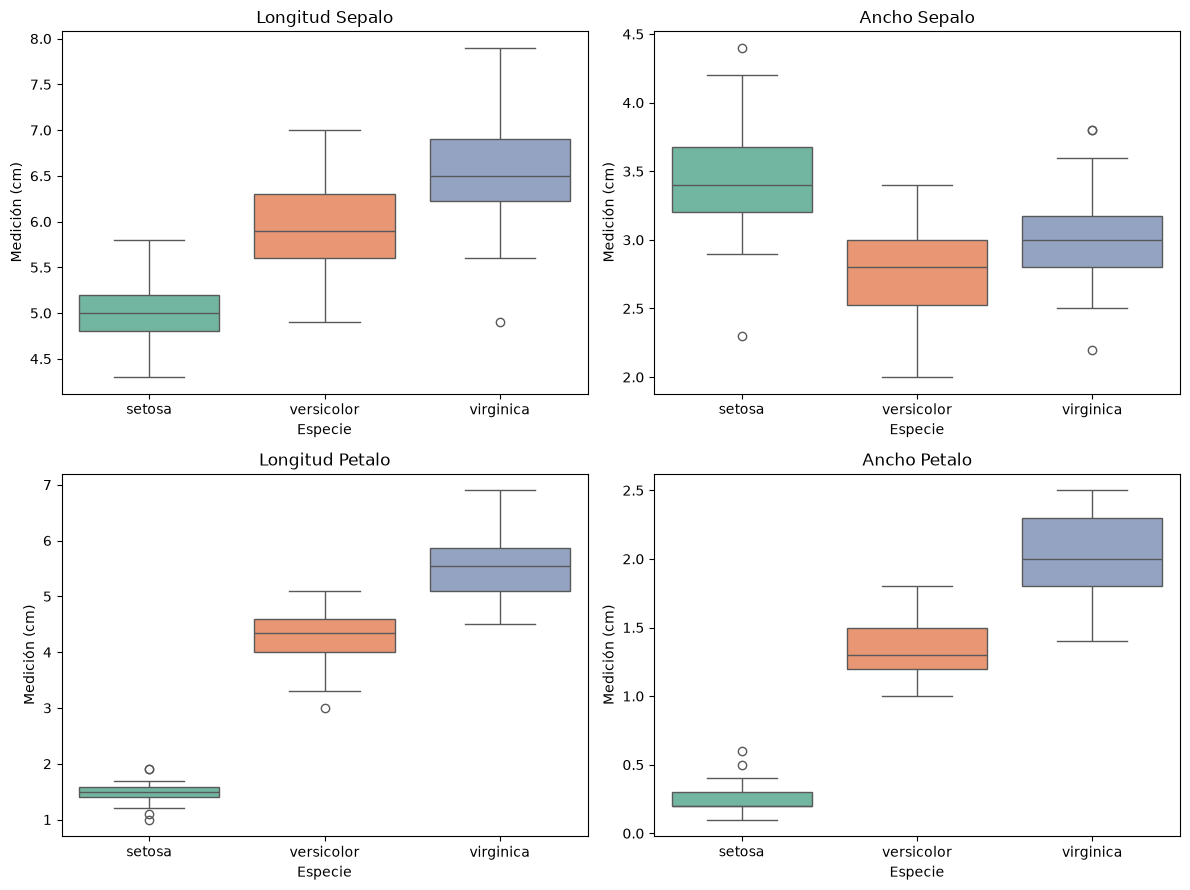

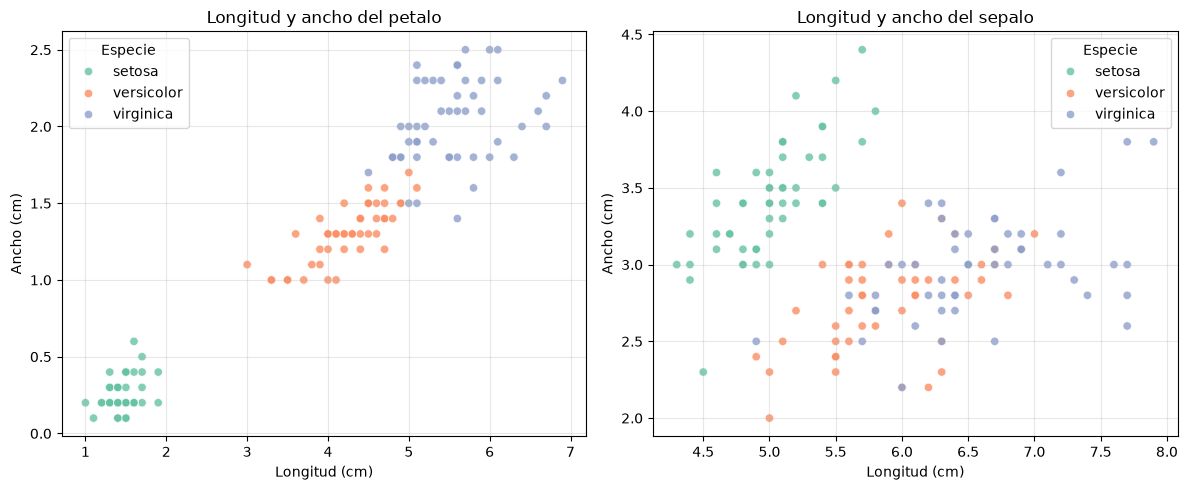

In [18]:
# Diagramas de caja para las cuatro variables
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for variable, ax in zip(variables_iris, axes.flat):
    sns.boxplot(data=df_iris, x='Especie', y=variable, hue='Especie',
                palette='Set2', legend=False, ax=ax)
    ax.set_title(variable.replace('_', ' '))
    ax.set_xlabel('Especie')
    ax.set_ylabel('Medición (cm)')
plt.tight_layout()
plt.show()

# Dispersión para pétalos y sépalos
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, parte in zip(axes, ['Petalo', 'Sepalo']):
    sns.scatterplot(data=df_iris, x=f'Longitud_{parte}', y=f'Ancho_{parte}',
                    hue='Especie', palette='Set2', alpha=0.8, ax=ax)
    ax.set_title(f'Longitud y ancho del {parte.lower()}')
    ax.set_xlabel('Longitud (cm)')
    ax.set_ylabel('Ancho (cm)')
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Lo que observo en las gráficas

Observo que setosa tiene pétalos más pequeños y virginica tiene los más grandes. Versicolor ocupa una posición intermedia. Las medidas de los sépalos se mezclan más entre especies, por lo que espero que las medidas de los pétalos ayuden más a distinguirlas.

Correlación entre las cuatro mediciones:


,Longitud_Sepalo,Ancho_Sepalo,Longitud_Petalo,Ancho_Petalo
Longitud_Sepalo,1.0000,-0.1176,0.8718,0.8179
Ancho_Sepalo,-0.1176,1.0000,-0.4284,-0.3661
Longitud_Petalo,0.8718,-0.4284,1.0000,0.9629
Ancho_Petalo,0.8179,-0.3661,0.9629,1.0000


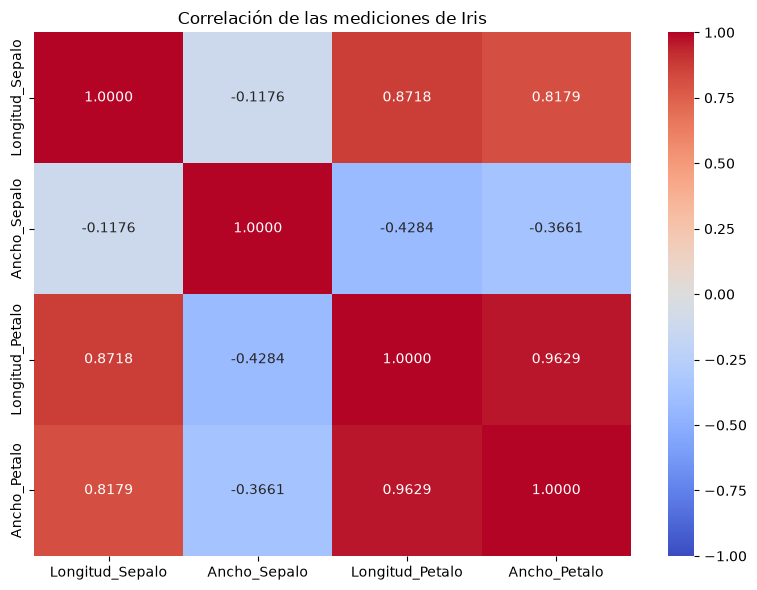

In [19]:
# Matriz de correlación
correlacion_iris = df_iris[variables_iris].corr()
print("Correlación entre las cuatro mediciones:")
display(correlacion_iris.round(4))
plt.figure(figsize=(8, 6))
sns.heatmap(correlacion_iris, annot=True, cmap='coolwarm', center=0,
            vmin=-1, vmax=1, fmt='.4f')
plt.title('Correlación de las mediciones de Iris')
plt.tight_layout()
plt.show()

La longitud y el ancho del pétalo tienen una correlación positiva alta, de aproximadamente **0.9629**. Al aumentar una medida, la otra suele aumentar también. Esta correlación corresponde a todas las flores juntas y puede reflejar diferencias entre especies; no necesariamente es igual dentro de cada especie.

In [20]:
# MANOVA: prueba principal
formula_iris = ' + '.join(variables_iris) + ' ~ Especie'
manova_iris = MANOVA.from_formula(formula_iris, data=df_iris)
resultado_iris = manova_iris.mv_test()
print(resultado_iris)

# Extraer los cuatro estadísticos correspondientes a Especie
resultados_mv_iris = resultado_iris.results['Especie']['stat'].astype(float)
print("\nCuatro estadísticos para el efecto de Especie:")
display(resultados_mv_iris.style.format({
    'Value': '{:.6f}', 'Num DF': '{:.0f}', 'Den DF': '{:.3f}',
    'F Value': '{:.4f}', 'Pr > F': '{:.3e}'
}))
for nombre, fila in resultados_mv_iris.iterrows():
    decision = 'Rechazo H₀' if fila['Pr > F'] < 0.05 else 'No rechazo H₀'
    print(f"{nombre}: p = {fila['Pr > F']:.3e} → {decision}")

                   Multivariate linear model
                                                                
----------------------------------------------------------------
       Intercept         Value  Num DF  Den DF   F Value  Pr > F
----------------------------------------------------------------
          Wilks' lambda  0.0170 4.0000 144.0000 2086.7720 0.0000
         Pillai's trace  0.9830 4.0000 144.0000 2086.7720 0.0000
 Hotelling-Lawley trace 57.9659 4.0000 144.0000 2086.7720 0.0000
    Roy's greatest root 57.9659 4.0000 144.0000 2086.7720 0.0000
----------------------------------------------------------------
                                                                
----------------------------------------------------------------
        Especie          Value  Num DF  Den DF   F Value  Pr > F
----------------------------------------------------------------
          Wilks' lambda  0.0234 8.0000 288.0000  199.1453 0.0000
         Pillai's trace  1.1919 8.0000 290.00

,Value,Num DF,Den DF,F Value,Pr > F
Wilks' lambda,0.023439,8,288.000,199.1453,1.365e-112
Pillai's trace,1.191899,8,290.000,53.4665,9.742e-53
Hotelling-Lawley trace,32.477320,8,203.402,582.1970,1.077e-135
Roy's greatest root,32.191929,4,145.000,1166.9574,3.787e-109


Wilks' lambda: p = 1.365e-112 → Rechazo H₀
Pillai's trace: p = 9.742e-53 → Rechazo H₀
Hotelling-Lawley trace: p = 1.077e-135 → Rechazo H₀
Roy's greatest root: p = 3.787e-109 → Rechazo H₀


### Interpretación del MANOVA

Los cuatro estadísticos tienen valores p menores a 0.05. La traza de Pillai es **1.1919** y lambda de Wilks es **0.0234**. Con estos resultados rechazo la hipótesis nula: las especies presentan diferencias en el conjunto de las cuatro mediciones. Esto todavía no indica qué pares de especies son distintos en cada variable. Los valores que la tabla general muestra como 0.0000 son números muy pequeños redondeados, no probabilidades exactamente iguales a cero.

In [21]:
# ANOVA por variable, con Bonferroni para las cuatro pruebas
alpha_iris = 0.05
alpha_bonferroni_iris = alpha_iris / len(variables_iris)
filas_anova_iris = []
anovas_iris = {}
for variable in variables_iris:
    modelo = ols(f'{variable} ~ Especie', data=df_iris).fit()
    tabla = sm.stats.anova_lm(modelo, typ=2)
    anovas_iris[variable] = tabla
    print(f"\nANOVA: {variable}")
    print(tabla.to_string(float_format=lambda x: f'{x:.6g}'))
    p = tabla.loc['Especie', 'PR(>F)']
    eta2 = tabla.loc['Especie', 'sum_sq'] / tabla['sum_sq'].sum()
    filas_anova_iris.append({
        'Variable': variable, 'F': tabla.loc['Especie', 'F'], 'p': p,
        'p ajustado Bonferroni': min(p * len(variables_iris), 1),
        'Eta cuadrada': eta2, 'Significativo': p < alpha_bonferroni_iris
    })
resumen_anova_iris = pd.DataFrame(filas_anova_iris).set_index('Variable')
print(f"\nAlfa de Bonferroni = {alpha_bonferroni_iris:.4f}")
display(resumen_anova_iris.style.format({
    'F': '{:.4f}', 'p': '{:.3e}', 'p ajustado Bonferroni': '{:.3e}', 'Eta cuadrada': '{:.4f}'
}))


ANOVA: Longitud_Sepalo
          sum_sq  df       F      PR(>F)
Especie  63.2121   2 119.265 1.66967e-31
Residual 38.9562 147     NaN         NaN

ANOVA: Ancho_Sepalo
          sum_sq  df     F      PR(>F)
Especie  11.3449   2 49.16 4.49202e-17
Residual  16.962 147   NaN         NaN

ANOVA: Longitud_Petalo
          sum_sq  df       F      PR(>F)
Especie  437.103   2 1180.16 2.85678e-91
Residual 27.2226 147     NaN         NaN

ANOVA: Ancho_Petalo
          sum_sq  df       F      PR(>F)
Especie  80.4133   2 960.007 4.16945e-85
Residual  6.1566 147     NaN         NaN

Alfa de Bonferroni = 0.0125


,F,p,p ajustado Bonferroni,Eta cuadrada,Significativo
Variable,,,,,
Longitud_Sepalo,119.2645,1.670e-31,6.679e-31,0.6187,True
Ancho_Sepalo,49.1600,4.492e-17,1.797e-16,0.4008,True
Longitud_Petalo,1180.1612,2.857e-91,1.143e-90,0.9414,True
Ancho_Petalo,960.0071,4.169e-85,1.668e-84,0.9289,True


Las cuatro variables siguen siendo significativas con **α = 0.0125**. En la comparación individual, la **longitud del pétalo** presenta el mayor F, de **1180.1612**, y la mayor eta cuadrada, de **0.9414**. Le sigue el ancho del pétalo con **F = 960.0071** y **eta cuadrada = 0.9289**. Por eso considero que las medidas del pétalo muestran las diferencias más claras entre especies.


Tukey HSD: Longitud_Sepalo
   Multiple Comparison of Means - Tukey HSD, FWER=0.05   
  group1     group2   meandiff p-adj lower  upper  reject
---------------------------------------------------------
    setosa versicolor     0.93   0.0 0.6862 1.1738   True
    setosa  virginica    1.582   0.0 1.3382 1.8258   True
versicolor  virginica    0.652   0.0 0.4082 0.8958   True
---------------------------------------------------------



Tukey HSD: Ancho_Sepalo
    Multiple Comparison of Means - Tukey HSD, FWER=0.05     
  group1     group2   meandiff p-adj   lower   upper  reject
------------------------------------------------------------
    setosa versicolor   -0.658    0.0 -0.8189 -0.4971   True
    setosa  virginica   -0.454    0.0 -0.6149 -0.2931   True
versicolor  virginica    0.204 0.0088  0.0431  0.3649   True
------------------------------------------------------------

Tukey HSD: Longitud_Petalo
   Multiple Comparison of Means - Tukey HSD, FWER=0.05   
  group1     group2   meandiff p-adj lower  upper  reject
---------------------------------------------------------
    setosa versicolor    2.798   0.0 2.5942 3.0018   True
    setosa  virginica     4.09   0.0 3.8862 4.2938   True
versicolor  virginica    1.292   0.0 1.0882 1.4958   True
---------------------------------------------------------



Tukey HSD: Ancho_Petalo
   Multiple Comparison of Means - Tukey HSD, FWER=0.05   
  group1     group2   meandiff p-adj lower  upper  reject
---------------------------------------------------------
    setosa versicolor     1.08   0.0 0.9831 1.1769   True
    setosa  virginica     1.78   0.0 1.6831 1.8769   True
versicolor  virginica      0.7   0.0 0.6031 0.7969   True
---------------------------------------------------------


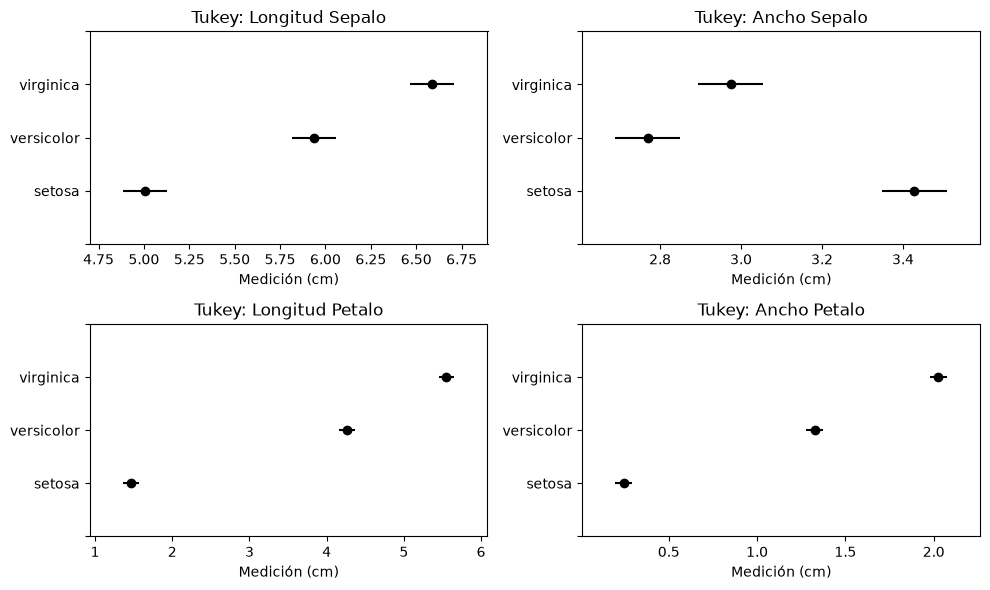

In [22]:
# Comparaciones múltiples post-hoc: Tukey HSD
# Tukey ajusta las tres comparaciones de especies dentro de cada variable.
tukeys_iris = {}
for variable in variables_iris:
    tukey = pairwise_tukeyhsd(df_iris[variable], df_iris['Especie'], alpha=0.05)
    tukeys_iris[variable] = tukey
    print(f"\nTukey HSD: {variable}")
    print(tukey)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for variable, ax in zip(variables_iris, axes.flat):
    tukeys_iris[variable].plot_simultaneous(ax=ax)
    ax.set_title(f'Tukey: {variable.replace("_", " ")}')
    ax.set_xlabel('Medición (cm)')
plt.tight_layout()
plt.show()

Con Tukey a un nivel de 0.05, los tres pares de especies son significativamente diferentes en cada una de las cuatro variables: **setosa–versicolor, setosa–virginica y versicolor–virginica**. En longitud del sépalo y en las dos medidas del pétalo, virginica tiene la media más alta y setosa la más baja. En ancho del sépalo, setosa tiene la media más alta, seguida de virginica y versicolor. Estas comparaciones ajustan el error dentro de cada variable, no entre las cuatro familias de comparaciones.

In [23]:
# Normalidad multivariada: Mardia por especie
filas_mardia_iris = []
for especie, grupo in df_iris.groupby('Especie'):
    resultados = mardia_test(grupo[variables_iris].to_numpy())
    filas_mardia_iris.append({'Especie': especie, **resultados})
normalidad_iris = pd.DataFrame(filas_mardia_iris).set_index('Especie')
display(normalidad_iris.round(6))
for especie, fila in normalidad_iris.iterrows():
    compatible = fila['Skewness p-value'] > 0.05 and fila['Kurtosis p-value'] > 0.05
    print(f"{especie}: " + ('No rechazo la normalidad multivariada.' if compatible
                            else 'Hay evidencia contra la normalidad multivariada.'))

,Skewness statistic,Skewness p-value,Kurtosis statistic,Kurtosis p-value
Especie,,,,
setosa,25.664345,0.177186,1.294992,0.195323
versicolor,25.185012,0.194444,-0.571866,0.567413
virginica,26.270598,0.157060,0.152614,0.878703


setosa: No rechazo la normalidad multivariada.
versicolor: No rechazo la normalidad multivariada.
virginica: No rechazo la normalidad multivariada.


In [24]:
# Homogeneidad de matrices de covarianza: M de Box
resultado_box_iris = box_m_test(df_iris[variables_iris], df_iris['Especie'])
for nombre, valor in resultado_box_iris.items():
    print(f"{nombre}: {valor:.3e}" if nombre == 'p-value' else f"{nombre}: {valor:.6f}")
if resultado_box_iris['p-value'] < 0.05:
    print("Rechazo H₀: las matrices de covarianza difieren entre las especies.")
    print("Doy prioridad a la traza de Pillai e interpreto los resultados con cautela.")
else:
    print("No rechazo H₀: no detecto diferencias entre las matrices de covarianza.")

# Revisión adicional para interpretar los ANOVA y Tukey
print("\nIgualdad de varianzas por variable: Levene centrado en la mediana")
filas_levene = []
for variable in variables_iris:
    muestras = [grupo[variable].to_numpy() for _, grupo in df_iris.groupby('Especie')]
    estadistico, p = stats.levene(*muestras, center='median')
    filas_levene.append({'Variable': variable, 'Estadístico': estadistico, 'p': p,
                         'Rechazo igualdad de varianzas': p < 0.05})
display(pd.DataFrame(filas_levene).set_index('Variable').style.format(
    {'Estadístico': '{:.4f}', 'p': '{:.3e}'}))

M statistic: 146.663249
Chi-square: 140.943050
df: 20.000000
p-value: 3.352e-20
Rechazo H₀: las matrices de covarianza difieren entre las especies.
Doy prioridad a la traza de Pillai e interpreto los resultados con cautela.

Igualdad de varianzas por variable: Levene centrado en la mediana


,Estadístico,p,Rechazo igualdad de varianzas
Variable,,,
Longitud_Sepalo,6.3527,2.259e-03,True
Ancho_Sepalo,0.5902,5.555e-01,False
Longitud_Petalo,19.4803,3.129e-08,True
Ancho_Petalo,19.8924,2.261e-08,True


### Interpretación de los supuestos

Mardia no detecta evidencia contra la normalidad multivariada en ninguna especie. Sin embargo, **M de Box sí detecta diferencias en las covarianzas**. Por eso no puedo afirmar que todos los supuestos se cumplan. Doy prioridad a Pillai y tomo en cuenta que los grupos tienen el mismo tamaño, pero eso no elimina el problema. Además, Levene detecta varianzas distintas en algunas variables, así que las comparaciones de Tukey solicitadas deben interpretarse con cautela. La independencia depende de cómo se seleccionaron las flores y no se demuestra con estas pruebas.

Proporción de separación discriminante por eje:
LD1: 99.12%
LD2: 0.88%

Promedios de los ejes por especie:


,LD1,LD2
Especie,,
setosa,7.608,0.215
versicolor,-1.825,-0.728
virginica,-5.783,0.513


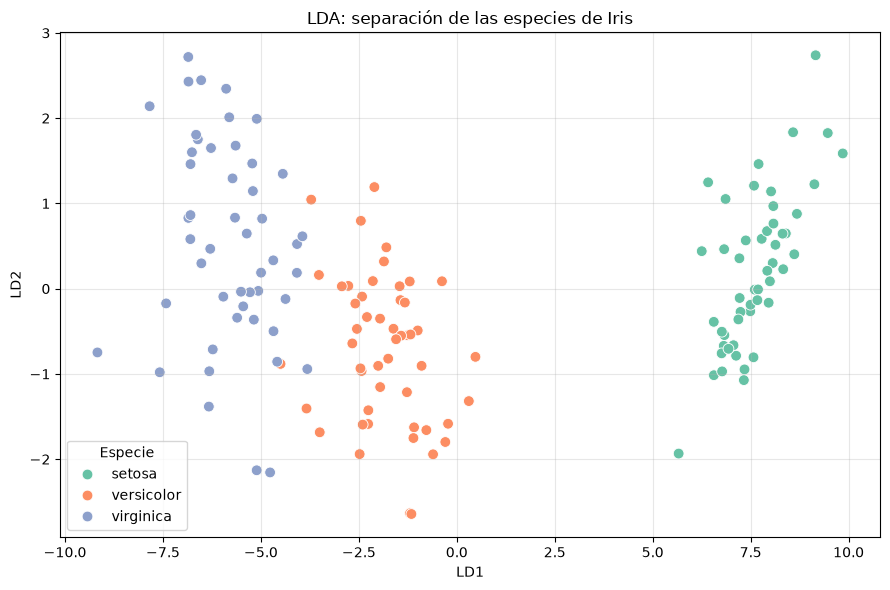

In [25]:
# LDA: visualizar la separación conjunta de las especies
lda_iris = LinearDiscriminantAnalysis(n_components=2)
coordenadas_iris = lda_iris.fit_transform(df_iris[variables_iris], df_iris['Especie'])
df_lda_iris = pd.DataFrame(coordenadas_iris, columns=['LD1', 'LD2'])
df_lda_iris['Especie'] = df_iris['Especie'].to_numpy()
print("Proporción de separación discriminante por eje:")
for i, proporcion in enumerate(lda_iris.explained_variance_ratio_, start=1):
    print(f"LD{i}: {proporcion:.2%}")
print("\nPromedios de los ejes por especie:")
display(df_lda_iris.groupby('Especie')[['LD1', 'LD2']].mean().round(3))
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df_lda_iris, x='LD1', y='LD2', hue='Especie', palette='Set2', s=60)
plt.title('LDA: separación de las especies de Iris')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Mis respuestas al análisis de Iris

**1. ¿Cuál de los cuatro estadísticos MANOVA es más apropiado y por qué?**

Yo elegiría la **traza de Pillai** porque la prueba M de Box indica que las matrices de covarianza no son iguales. Pillai suele ser más resistente ante este problema. Su valor es **1.1919**, con **F = 53.4665** y un valor p menor a 0.05. Concluyo que existen diferencias conjuntas entre las especies, aunque la falta de igualdad de covarianzas exige interpretar el resultado con cuidado.

**2. ¿Qué variable dependiente contribuye más a las diferencias entre grupos?**

En los ANOVA individuales, la **longitud del pétalo** es la variable que más distingue a las especies, con **F = 1180.1612** y **eta cuadrada = 0.9414**. Esto significa que alrededor de **94.14 %** de la variación de esa medida se relaciona con las diferencias entre especies en esta muestra. El ancho del pétalo también destaca, con aproximadamente **92.89 %**. Estos resultados comparan las variables por separado; como las medidas están relacionadas, no los interpreto como aportaciones independientes al MANOVA.

**3. ¿Qué pares de grupos son significativamente diferentes?**

Según Tukey con α = 0.05, encuentro diferencias en los tres pares: **setosa y versicolor**, **setosa y virginica**, y **versicolor y virginica**, para las cuatro mediciones. Por ejemplo, la longitud promedio del pétalo es **1.462 cm** en setosa, **4.260 cm** en versicolor y **5.552 cm** en virginica. El ajuste de Tukey corresponde a cada variable. Como algunas varianzas son distintas, considero estas comparaciones con cautela.

**4. ¿Se cumplen los supuestos del MANOVA? ¿Qué implicaciones tiene?**

No se cumplen todos de la misma manera. Mardia no rechaza la normalidad multivariada en las tres especies, pero M de Box sí rechaza la igualdad de covarianzas, con **p ≈ 3.352 × 10⁻²⁰**. Hay **50 flores por especie**, lo cual ayuda a tener grupos equilibrados. Aun así, esto no corrige por completo las covarianzas diferentes. Por eso uso Pillai como referencia y evito presentar el resultado como si todos los supuestos estuvieran comprobados. También reconozco que la independencia depende del muestreo.

**5. ¿Cómo se relacionan los resultados del LDA con los del MANOVA?**

El MANOVA indica diferencias entre las medias conjuntas y el LDA me permite observar la separación usando las cuatro medidas al mismo tiempo. El primer eje reúne aproximadamente **99.12 %** de la separación discriminante y el segundo **0.88 %**. En la gráfica, setosa se distingue claramente, mientras que versicolor y virginica presentan cierta mezcla. Esto coincide con las diferencias detectadas por MANOVA, pero no implica una clasificación perfecta. Además, como el LDA también supone covarianzas iguales, lo uso principalmente para describir la separación observada.

### Mi conclusión

Con este análisis concluyo que las tres especies de Iris tienen diferencias en sus mediciones. Las características del pétalo muestran las diferencias más claras. El MANOVA, los ANOVA y el LDA apoyan esa observación, aunque la falta de igualdad de covarianzas y de algunas varianzas hace necesario interpretar las pruebas con cautela.

### Referencias para los procedimientos

- [MANOVA en statsmodels](https://www.statsmodels.org/stable/generated/statsmodels.multivariate.manova.MANOVA.html).
- [LDA en scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.discriminant_analysis.LinearDiscriminantAnalysis.html).
- [Prueba de Mardia y normalización de la covarianza](https://search.r-project.org/CRAN/refmans/mvnormalTest/html/mardia.html).
- [Estadísticos multivariados y elección de Pillai](https://stat.ethz.ch/R-manual/R-devel/library/stats/html/summary.manova.html).
